# Visualization Guide Demo

This notebook demonstrates common chart types using the Oracle `FOOD_ANALYSIS` data and explains when to use each one.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv()
connection_url = URL.create(
    "oracle+oracledb",
    username=os.environ["ORACLE_USER"],
    password=os.environ["ORACLE_PASSWORD"],
    host="localhost",
    port=1522,
    query={"service_name": "FREEPDB1"},
)
engine = create_engine(connection_url)


## 1. Bar chart ? compare categories
**Use when:** comparing values across categories (rankings, top N, category totals).
**Avoid when:** you have too many categories or need to show precise trend over time.

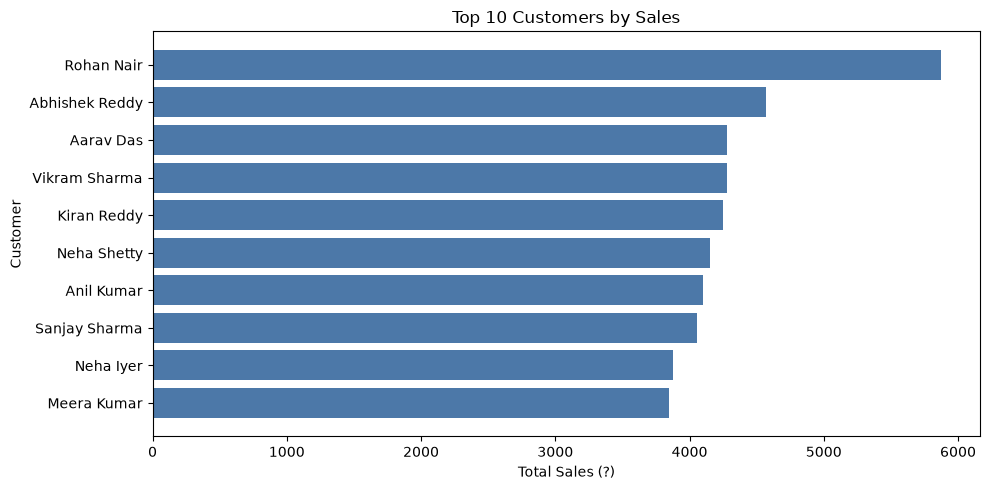

In [2]:
top_customers = pd.read_sql("""
SELECT customer_name, SUM(order_amount) AS total_sales
FROM customers c JOIN orders o ON c.customer_id = o.customer_id
GROUP BY customer_name
ORDER BY total_sales DESC
FETCH FIRST 10 ROWS ONLY
""", engine)

plt.figure(figsize=(10,5))
plt.barh(top_customers['customer_name'], top_customers['total_sales'], color='#4C78A8')
plt.gca().invert_yaxis()
plt.title('Top 10 Customers by Sales')
plt.xlabel('Total Sales (?)')
plt.ylabel('Customer')
plt.tight_layout()
plt.show()


## 2. Line chart ? trend over time
**Use when:** showing change over time (daily/weekly/monthly trend).
**Avoid when:** categories have no natural order.

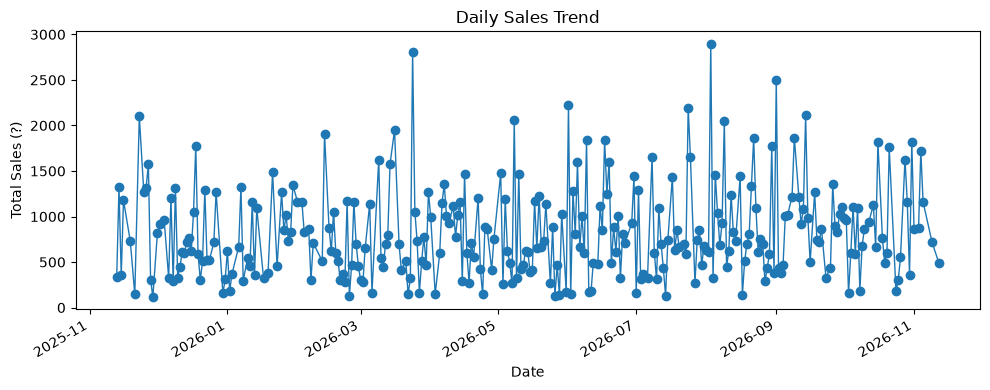

In [3]:
daily_sales = pd.read_sql("""
SELECT TRUNC(order_placed_at) AS order_day, COUNT(*) AS total_orders, SUM(order_amount) AS total_sales
FROM orders
GROUP BY TRUNC(order_placed_at)
ORDER BY order_day
""", engine)
daily_sales['order_day'] = pd.to_datetime(daily_sales['order_day'])

plt.figure(figsize=(10,4))
plt.plot(daily_sales['order_day'], daily_sales['total_sales'], marker='o', linewidth=1)
plt.title('Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Sales (?)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


## 3. Histogram ? distribution
**Use when:** understanding spread, skew, and common ranges of a numeric metric.
**Avoid when:** you need exact values for each category.

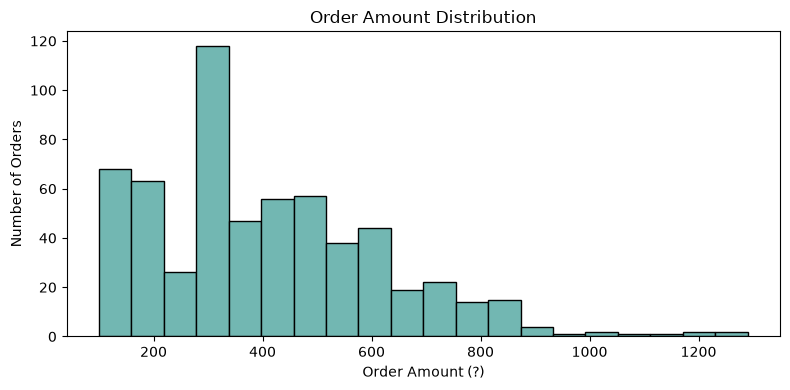

In [4]:
order_amounts = pd.read_sql("SELECT order_amount FROM orders", engine)
plt.figure(figsize=(8,4))
plt.hist(order_amounts['order_amount'], bins=20, color='#72B7B2', edgecolor='black')
plt.title('Order Amount Distribution')
plt.xlabel('Order Amount (?)')
plt.ylabel('Number of Orders')
plt.tight_layout()
plt.show()


## 4. Scatter plot ? relationship between numeric variables
**Use when:** checking correlation, clusters, or outliers between two numeric measures.
**Avoid when:** there is no meaningful numeric relationship.

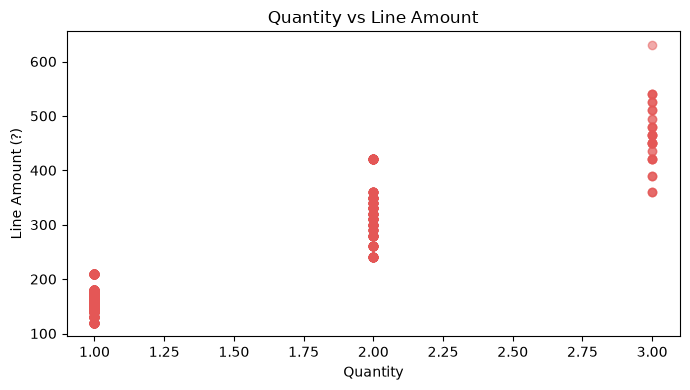

In [5]:
items = pd.read_sql("SELECT quantity, line_amount, unit_price FROM order_items", engine)
plt.figure(figsize=(7,4))
plt.scatter(items['quantity'], items['line_amount'], alpha=0.5, color='#E45756')
plt.title('Quantity vs Line Amount')
plt.xlabel('Quantity')
plt.ylabel('Line Amount (?)')
plt.tight_layout()
plt.show()


## 5. Stacked bar ? composition across categories
**Use when:** comparing totals and composition at the same time.
**Avoid when:** there are too many segments; consider 100% stacked bar for share comparison.

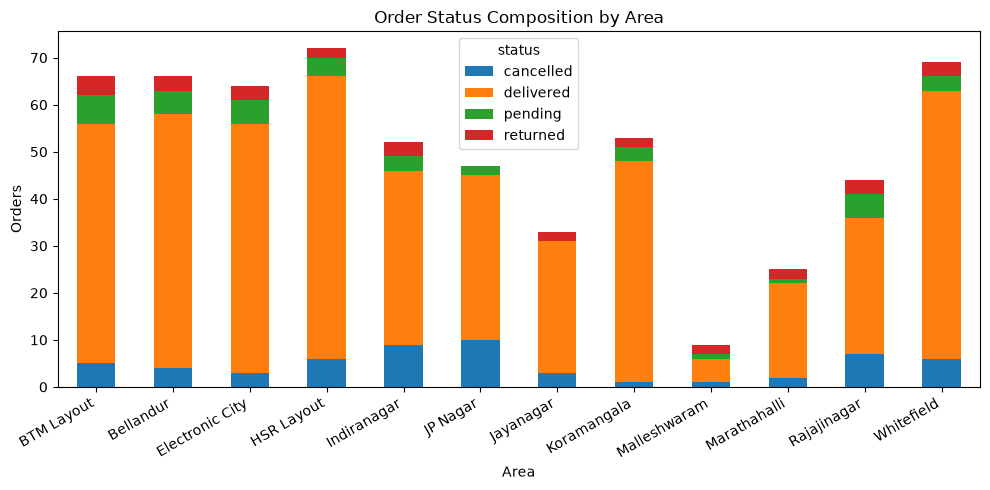

In [6]:
status_by_area = pd.read_sql("""
SELECT c.area, o.status, COUNT(*) AS order_count
FROM orders o JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.area, o.status
ORDER BY c.area, o.status
""", engine)
pivot = status_by_area.pivot(index='area', columns='status', values='order_count').fillna(0)
pivot.plot(kind='bar', stacked=True, figsize=(10,5))
plt.title('Order Status Composition by Area')
plt.xlabel('Area')
plt.ylabel('Orders')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


## 6. Heatmap-style pivot table ? matrix comparison
**Use when:** comparing a metric across two dimensions (area x category, month x product).
**Avoid when:** exact row-level detail is needed; use a table instead.

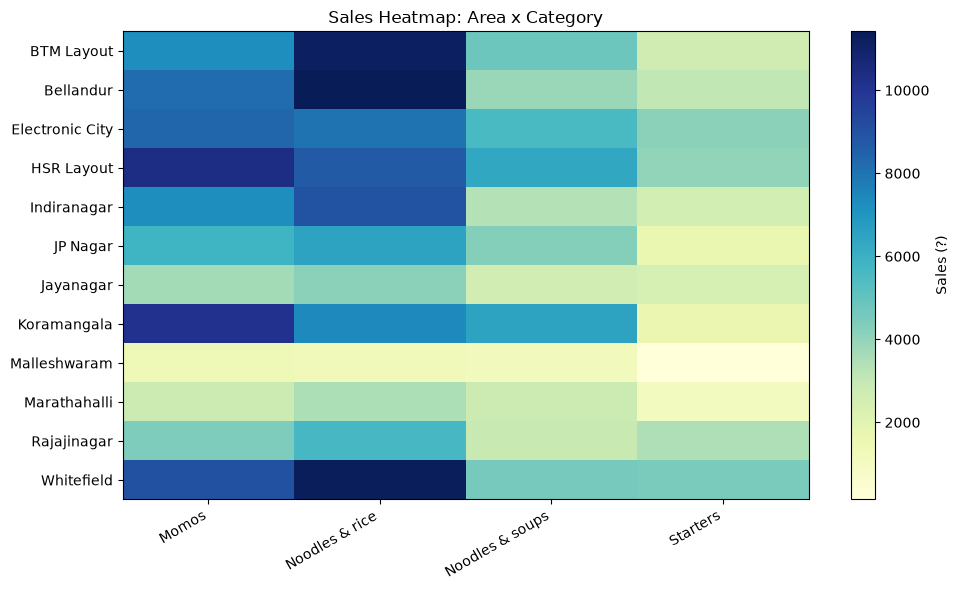

In [7]:
matrix = pd.read_sql("""
SELECT c.area, p.category, SUM(oi.line_amount) AS sales
FROM order_items oi
JOIN orders o ON oi.order_id = o.order_id
JOIN customers c ON o.customer_id = c.customer_id
JOIN products p ON oi.product_id = p.product_id
GROUP BY c.area, p.category
""", engine)
pivot = matrix.pivot(index='area', columns='category', values='sales').fillna(0)

plt.figure(figsize=(10,6))
plt.imshow(pivot.values, aspect='auto', cmap='YlGnBu')
plt.colorbar(label='Sales (?)')
plt.xticks(range(len(pivot.columns)), pivot.columns, rotation=30, ha='right')
plt.yticks(range(len(pivot.index)), pivot.index)
plt.title('Sales Heatmap: Area x Category')
plt.tight_layout()
plt.show()
